# Final project · From the starting grid to a pre-race prediction
## Formula 1 World Championship, 2014–2024 — one notebook with every number used in the final presentation

**Business Intelligence · IIB423T-1 · Universidad del Desarrollo** — **Group 06**: Maximiliano Sandoval Mosser and
Benjamín Toloza Cossio · Instructor: Tomás Fontecilla · November 2026

**Purpose.** This notebook closes the project. It recomputes, from the project files and with fixed seeds, every figure
quoted in the final presentation, so that the story has **one source of truth**:

| Part | Stage of the project | Content |
|---|---|---|
| 1 | Choosing the question | Why pit-stop times were not used |
| 2 | Preparing the data | Population flow from the raw files to the analytic table |
| 3 | Measuring the relationship | IDC, points by grid block, pole wins, association vs effect, circuits, lap 1, exact zeros |
| 4 | Trusting the data | Validation checks, leakage audit and the 25 % subsample (from W2) |
| 5 | Predicting who scores | Season-by-season (walk-forward) evaluation, validation, final test, what the model adds, limits |
| 6 | Robustness | Same predictions as the C2 design; training only on the 2022 rules; shorter windows |
| 7 | Outputs | Figures (shared visual system) and `final_key_numbers.json` for the slides |

**Run order.** `analysis/01` → `02` → `03` → `notebooks/W2_project.ipynb` → `notebooks/2_C2_model.ipynb` → **this notebook**.
It reads `data/raw/` and `data/processed/analytic_driver_race_2014_2024_w2.csv`, and writes `data/processed/final_*`
and `analysis/figures/FINAL_*`. Every random step uses the seed 2026.

**Reading rule.** All relationships below are **associations** measured on past races. None of them is the effect of
moving a car to another starting position.

**Data files (C3).** Following the C3 rules, the data files are not included in the repository: the outputs below were
saved when the notebook was executed and can be read without running it (README, part 6).

## 0. Setup

In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def find_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "raw" / "races.csv").exists():
            return base
    raise FileNotFoundError("data/raw/races.csv not found: open the whole GROUP_06_C1 folder.")

ROOT = find_root()
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "analysis" / "figures"
os.makedirs(FIG, exist_ok=True)
SEED = 2026
read = lambda f: pd.read_csv(RAW / f, na_values="\\N")

at = pd.read_csv(PROC / "analytic_driver_race_2014_2024_w2.csv", parse_dates=["date"])
fin = at[at["finished"] & at["grid"].notna()].copy()          # finishers with a grid slot (population of rho and IDC)
KEY = {}                                                      # every number quoted in the presentation
print(f"Analytic table: {len(at):,} rows x {at.shape[1]} columns | races: {at['raceId'].nunique()} | "
      f"seasons: {at['year'].min()}–{at['year'].max()}")
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

Analytic table: 4,606 rows x 45 columns | races: 227 | seasons: 2014–2024
pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | matplotlib 3.11.2


In [2]:
def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return c - h, c + h

def race_rho(d, x="grid", y="final_pos", min_n=8):
    """Spearman rho between x and y inside each race (needs >= min_n drivers): one value per race."""
    return d.dropna(subset=[x, y]).groupby("raceId")[[x, y]].apply(
        lambda g: stats.spearmanr(g[x], g[y])[0] if len(g) >= min_n else np.nan).rename("rho")

def partial_spearman(x, y, z):
    r = np.corrcoef([stats.rankdata(x), stats.rankdata(y), stats.rankdata(z)])
    return (r[0, 1] - r[0, 2] * r[1, 2]) / np.sqrt((1 - r[0, 2]**2) * (1 - r[1, 2]**2))

def holm(p):
    p = np.asarray(p); m = len(p); order = np.argsort(p); adj = np.empty(m); run = 0
    for k, i in enumerate(order):
        run = max(run, (m - k) * p[i]); adj[i] = min(1, run)
    return adj

## 1. Choosing the question: why not pit-stop times
The first candidate line was pit-stop efficiency. The recorded duration is the **whole time in the pit lane** (entry to
exit), so it depends on the length of each circuit's pit lane, not only on the crew. We measure how much of its variation
the circuit explains (stops of 60 s or less, i.e. without red-flag stoppages, 2014–2024).

In [3]:
races = read("races.csv"); pit = read("pit_stops.csv")
pit = pit.merge(races[["raceId", "year", "circuitId"]], on="raceId")
pit = pit[pit["year"].between(2014, 2024) & (pit["milliseconds"] <= 60000)].assign(s=lambda d: d["milliseconds"] / 1000)
grand = pit["s"].mean()
ss_between = pit.groupby("circuitId")["s"].apply(lambda v: len(v) * (v.mean() - grand) ** 2).sum()
eta2 = ss_between / ((pit["s"] - grand) ** 2).sum()
KEY["pit_eta2"] = round(eta2, 3)
print(f"Pit stops analysed: {len(pit):,} | share of variation explained by the circuit (eta squared) = {eta2:.3f}")

Pit stops analysed: 7,851 | share of variation explained by the circuit (eta squared) = 0.378


**Observation.** The circuit alone explains about 38 % of the variation of the recorded pit-stop time, so the measure
mixes the crew's work with the geometry of each pit lane. The starting position and the finishing position, on the other
hand, are observed directly for every driver. We therefore study **starting position → result**.

## 2. Preparing the data: from the raw files to the analytic table

In [4]:
results_raw, lap_times = read("results.csv"), read("lap_times.csv")
period_ids = set(races.loc[races["year"].between(2014, 2024), "raceId"])
laps_per_race = lap_times[lap_times["raceId"].isin(period_ids)].groupby("raceId")["lap"].max()
flow = pd.DataFrame([
    ("Raw results, 1950–2024", len(results_raw), "results.csv (14 source files, 12 used)"),
    ("Results in seasons 2014–2024", int(results_raw["raceId"].isin(period_ids).sum()), "one engine formula, one points scale, complete tables"),
    ("Analytic table", len(at), "Belgium 2021 excluded: 1 lap behind the safety car, so its order copies the grid"),
    ("Finishers with a grid slot", len(fin), "population of the per-race correlation"),
], columns=["population", "rows", "reason"])
KEY.update(rows=len(at), races=int(at["raceId"].nunique()), raw_results=len(results_raw),
           period_results=int(results_raw["raceId"].isin(period_ids).sum()), finishers=len(fin),
           pitlane_starts=int(at["pitlane_start"].sum()))
flow

,population,rows,reason
0,"Raw results, 1950–2024",26759,"results.csv (14 source files, 12 used)"
1,Results in seasons 2014–2024,4626,"one engine formula, one points scale, complete..."
2,Analytic table,4606,Belgium 2021 excluded: 1 lap behind the safety...
3,Finishers with a grid slot,3751,population of the per-race correlation


## 3. Measuring the relationship
### 3.1 IDC: how closely the finishing order follows the grid
For each race we compute the Spearman rank correlation between grid slot and finishing position among the finishers
(**+1** = same order as the grid, **0** = no relation, **−1** = reversed order). The **IDC** is the median over races. Its
95 % interval resamples whole races (5,000 bootstrap samples).

In [5]:
rho = race_rho(fin)
rng = np.random.default_rng(SEED)
meds = np.median(rng.choice(rho.dropna().to_numpy(), (5000, rho.notna().sum())), axis=1)
idc, idc_lo, idc_hi = rho.median(), *np.percentile(meds, [2.5, 97.5])
season_idc = rho.to_frame().join(at.groupby("raceId")["year"].first()).groupby("year")["rho"].median()
KEY.update(idc=round(idc, 3), idc_lo=round(idc_lo, 3), idc_hi=round(idc_hi, 3), races_with_rho=int(rho.notna().sum()),
           rho_min=round(rho.min(), 2), rho_negative=int((rho < 0).sum()),
           idc_2023=round(season_idc.loc[2023], 3), idc_2024=round(season_idc.loc[2024], 3))
print(f"IDC = {idc:.3f} (95 % CI {idc_lo:.3f}–{idc_hi:.3f}) over {rho.notna().sum()} races | "
      f"lowest race rho = {rho.min():.2f}; races with rho < 0: {(rho < 0).sum()}")
season_idc.round(3).to_frame("IDC by season")

IDC = 0.811 (95 % CI 0.792–0.835) over 227 races | lowest race rho = -0.09; races with rho < 0: 1


,IDC by season
year,
2014,0.802
2015,0.860
2016,0.835
2017,0.800
2018,0.824
2019,0.854
2020,0.777
2021,0.789
2022,0.749


### 3.2 What a grid slot is worth: points by grid block, pole wins
Denominator: **all starters with a grid slot** (retirements included), because that is the chance a strategist faces
before the start.

In [6]:
starters = at[at["grid"].notna()].copy()
starters["block"] = pd.cut(starters["grid"], [0, 3, 6, 10, 15, 30], labels=["1–3", "4–6", "7–10", "11–15", "16+"])
blk = starters.groupby("block", observed=True)["top10"].agg(scored="sum", starters="size")
blk["P(top 10)"] = blk["scored"] / blk["starters"]
blk[["CI low", "CI high"]] = np.array([wilson(k, n) for k, n in zip(blk["scored"], blk["starters"])])
poles = starters[starters["grid"] == 1]
KEY["top10_by_block"] = {b: round(v, 3) for b, v in blk["P(top 10)"].items()}
KEY.update(pole_win=round(poles["win"].mean(), 3), pole_wins=int(poles["win"].sum()), poles=len(poles))
print(f"Pole sitters who won: {int(poles['win'].sum())} of {len(poles)} ({poles['win'].mean():.1%})")
blk.round(3)

Pole sitters who won: 118 of 227 (52.0%)


,scored,starters,P(top 10),CI low,CI high
block,,,,,
1–3,609,679,0.897,0.872,0.918
4–6,552,681,0.811,0.779,0.838
7–10,567,905,0.627,0.595,0.657
11–15,371,1128,0.329,0.302,0.357
16+,157,1136,0.138,0.119,0.159


### 3.3 Association, not effect: holding team strength fixed
A fast car tends to qualify well **and** to finish well, so part of the grid–result agreement goes with the car. The
partial correlation measures the grid–result association among drivers whose teams had the **same championship rank
before the race** (a coarse proxy for car strength). Intervals resample whole races (1,000 samples).

In [7]:
pdat = fin.dropna(subset=["constructor_rank_prev"])
by_race = {r: g[["grid", "final_pos", "constructor_rank_prev"]].to_numpy() for r, g in pdat.groupby("raceId")}
ids = np.array(list(by_race)); rng = np.random.default_rng(SEED); boot = []
for _ in range(1000):
    s = np.vstack([by_race[r] for r in rng.choice(ids, len(ids))])
    boot.append((stats.spearmanr(s[:, 0], s[:, 1])[0], partial_spearman(s[:, 0], s[:, 1], s[:, 2])))
boot = np.array(boot)
pooled = stats.spearmanr(pdat["grid"], pdat["final_pos"])[0]
partial = partial_spearman(pdat["grid"], pdat["final_pos"], pdat["constructor_rank_prev"])
(lo1, lo2), (hi1, hi2) = np.percentile(boot, 2.5, axis=0), np.percentile(boot, 97.5, axis=0)
KEY.update(pooled=round(pooled, 3), partial=round(partial, 3), partial_lo=round(lo2, 3), partial_hi=round(hi2, 3))
print(f"Pooled rho(grid, final) = {pooled:.3f} (CI {lo1:.3f}–{hi1:.3f}) | holding team rank fixed = {partial:.3f} "
      f"(CI {lo2:.3f}–{hi2:.3f})")

Pooled rho(grid, final) = 0.769 (CI 0.749–0.789) | holding team rank fixed = 0.498 (CI 0.464–0.534)


**Observation.** The association drops from 0.77 to 0.50 but stays clearly positive. This is **consistent with** car
strength acting on both the grid and the result; it does not measure the car's effect, nor the effect of the grid
(driver skill, reliability and penalties are not held fixed, and nothing was assigned at random). Note that 0.77 (pooled
over all finishers) and 0.81 (IDC, median of per-race values) are different measures.

### 3.4 Do circuits differ? 19 comparisons at once

In [8]:
rc = rho.to_frame().join(at.groupby("raceId")["circuit"].first())
n_c = rc.groupby("circuit")["rho"].count(); circs = n_c[n_c >= 5].index
kw = stats.kruskal(*[rc.loc[rc["circuit"] == c, "rho"].dropna() for c in circs])
p_raw = [stats.mannwhitneyu(rc.loc[rc["circuit"] == c, "rho"].dropna(), rc.loc[rc["circuit"] != c, "rho"].dropna()).pvalue
         for c in circs]
p_holm = holm(p_raw)
KEY.update(n_circuits=len(circs), kw_p=round(kw.pvalue, 2), raw_sig=int((np.array(p_raw) < .05).sum()),
           holm_sig=int((p_holm < .05).sum()), monaco_holm=round(float(p_holm[list(circs).index("Monte-Carlo")]), 2))
print(f"{len(circs)} circuits with >= 5 races | Kruskal–Wallis p = {kw.pvalue:.2f} | unadjusted p < 0.05: "
      f"{(np.array(p_raw) < .05).sum()} | after Holm correction: {(p_holm < .05).sum()} (Monaco Holm p = {KEY['monaco_holm']})")

19 circuits with >= 5 races | Kruskal–Wallis p = 0.29 | unadjusted p < 0.05: 2 | after Holm correction: 0 (Monaco Holm p = 0.38)


**Observation.** No circuit is distinguishable from the others once we account for comparing 19 circuits at the same
time. Differences in the circuit IDC are within the noise of 7–13 races per circuit.

### 3.5 How much happens on lap 1
Position changes are counted **lap by lap** from `lap_times` (the grid is "lap 0"), among finishers.

In [9]:
lt = lap_times[lap_times["raceId"].isin(at["raceId"])].sort_values(["raceId", "driverId", "lap"]).copy()
lt["prev"] = lt.groupby(["raceId", "driverId"])["position"].shift()
lt = lt.merge(at[["raceId", "driverId", "grid"]], on=["raceId", "driverId"], how="left", validate="many_to_one")
lt.loc[lt["lap"] == 1, "prev"] = lt.loc[lt["lap"] == 1, "grid"]
lt["change"] = (lt["position"] - lt["prev"]).abs()
pits = read("pit_stops.csv")[["raceId", "driverId", "lap"]]
own = pd.concat([pits, pits.assign(lap=pits["lap"] + 1)]).drop_duplicates().assign(own_pit=True)
lt = lt.merge(own, on=["raceId", "driverId", "lap"], how="left", validate="many_to_one")
lt["own_pit"] = lt["own_pit"].fillna(False).astype(bool)
ltf = lt.merge(fin.dropna(subset=["pos_lap1"])[["raceId", "driverId"]], on=["raceId", "driverId"])
share = lambda d: d.loc[d["lap"] == 1, "change"].sum() / d["change"].sum()
lap1_all, lap1_nopit = share(ltf), share(ltf[~ltf["own_pit"]])
intensity = ltf.loc[ltf["lap"] == 1, "change"].mean() / ltf.loc[ltf["lap"] > 1, "change"].mean()
KEY.update(lap1_share_low=round(lap1_all, 3), lap1_share_high=round(lap1_nopit, 3), lap1_intensity=round(intensity, 1))
print(f"Lap-1 share of all position changes: {lap1_all:.1%} (all laps) to {lap1_nopit:.1%} (excluding the driver's own "
      f"pit laps) | lap 1 moves {intensity:.1f}x more places than an average later lap")

Lap-1 share of all position changes: 9.9% (all laps) to 13.1% (excluding the driver's own pit laps) | lap 1 moves 6.5x more places than an average later lap


### 3.6 Many finishers end exactly where they started

In [10]:
pg = fin["positions_gained"].astype(int).value_counts(normalize=True)
ratio = pg.loc[0] / ((pg.loc[-1] + pg.loc[1]) / 2)
fin_p1, fin_back = fin[fin["grid"] == 1], fin[fin["grid"] >= 16]
KEY.update(zero_share=round(pg.loc[0], 3), zero_ratio=round(ratio, 2),
           zero_p1=round((fin_p1["positions_gained"] == 0).mean(), 2), zero_p16=round((fin_back["positions_gained"] == 0).mean(), 2))
print(f"Finishers ending exactly in their grid slot: {pg.loc[0]:.1%} ({ratio:.2f}x the average of the neighbours -1/+1) | "
      f"from P1: {KEY['zero_p1']:.0%} of finishers | from P16 or further back: {KEY['zero_p16']:.0%}")

Finishers ending exactly in their grid slot: 16.8% (1.48x the average of the neighbours -1/+1) | from P1: 57% of finishers | from P16 or further back: 6%


**Observation.** Zero is over-represented (zero-inflated), mainly at the front: a pole sitter cannot gain places, so
"0 gained" is the only good outcome there. It is a **boundary effect** of a bounded variable. The IDC and the points
probability do not use positions gained, so they are not affected; averages of positions gained would be misleading.

## 4. Trusting the data (summary of W2)

In [11]:
checks = pd.read_csv(PROC / "w2_validation_checks.csv"); audit = pd.read_csv(PROC / "w2_leakage_audit.csv")
race_tab = rho.to_frame().join(at.groupby("raceId")["year"].first())
reps = np.array([np.median(np.concatenate([np.random.default_rng(SEED + b).choice(
    g["rho"].dropna().to_numpy(), int(round(.25 * len(g))), replace=False) for _, g in race_tab.groupby("year")]))
    for b in range(1000)])
KEY.update(checks=len(checks), checks_pass=int((checks["result"] == "pass").sum()), leakage_risks=len(audit),
           sub_mean=round(reps.mean(), 3), sub_sd=round(reps.std(ddof=1), 3))
print(f"Validation checks: {len(checks)} ({KEY['checks_pass']} pass, {len(checks) - KEY['checks_pass']} flagged and kept "
      f"with a reason) | leakage risks audited: {len(audit)} | IDC in 1,000 random 25 % subsamples of races: "
      f"mean {reps.mean():.3f}, SD {reps.std(ddof=1):.3f}")
checks[["id", "check", "violations", "result"]]

Validation checks: 15 (11 pass, 4 flagged and kept with a reason) | leakage risks audited: 8 | IDC in 1,000 random 25 % subsamples of races: mean 0.814, SD 0.021


,id,check,violations,result
0,C01,Unique key,0,pass
1,C02,Types,0,pass
2,C03,Missing identifiers,0,pass
3,C04,Raw → analytic reconciliation,0,pass
4,C05,Grid range,0,pass
5,C06,Final order,0,pass
6,C07,Race-level counts,0,pass
7,C08,Category consistency,1,flag
8,C09,Points rule,0,pass
9,C10,Status anomaly,1,flag


## 5. Predicting who scores points
**Question.** Before the start, will this driver finish in the points (top 10)? **One row** = one driver in one race.
**Positive class** = finishes 1st–10th (exactly 10 per race, about 49 % of rows).

**Prediction moment (T1).** The grid is published and the race has not started. Only four inputs exist then: grid slot
(a pit-lane start is placed behind the last slot), pit-lane flag, the team's championship rank **after the previous
round**, and the qualifying gap to the fastest qualifier. Anything observed during or after the race is excluded.

**Model and reference.** A logistic regression (standardised inputs, median imputation, L2 with C = 1, threshold 0.5),
compared with the **grid rule**: "the top 10 on the grid score points".

**Season-by-season (walk-forward) evaluation.** Each season is predicted by a model trained on **all earlier seasons
only**, so every prediction looks one season ahead, as a strategist would. Seasons 2018–2022 are the **validation**
seasons, where the choices were checked; 2023–2024 are the **test** seasons, evaluated once with the specification frozen.
Whole seasons are used, so no race is ever split between training and prediction.

In [12]:
at["grid_filled"] = at["grid"].fillna(at["starters_in_race"])
at["pitlane"] = at["pitlane_start"].astype(int)
FEATURES = ["grid_filled", "pitlane", "constructor_rank_prev", "quali_gap_pct"]
TARGET = "top10"
AFTER_START = ["pos_lap1", "gained_lap1", "race_pace_gap_pct", "fastest_lap_rank", "final_pos", "position",
               "positions_gained", "finished", "classified", "status", "points", "laps", "circuit_races"]
assert not set(FEATURES) & set(AFTER_START + [TARGET])           # no information from during or after the race

def make_model():
    prep = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                                                ("scale", StandardScaler())]), FEATURES)])
    return Pipeline([("prep", prep), ("logit", LogisticRegression(C=1.0, max_iter=1000))])

def scores(y, yhat):
    return {"accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat),
            "recall": recall_score(y, yhat), "F1": f1_score(y, yhat)}

PRED, plan, models = [], [], {}
for season in range(2018, 2025):
    train, target = at[at["year"] < season], at[at["year"] == season]
    assert train["date"].max() < target["date"].min() and set(train["raceId"]).isdisjoint(target["raceId"])
    m = make_model().fit(train[FEATURES], train[TARGET]); models[season] = m
    p = m.predict_proba(target[FEATURES])[:, 1]
    PRED.append(target[["raceId", "driverId", "year", "grid", "team_tier", "finished", TARGET]].assign(
        p=p, model=(p >= 0.5).astype(int), reference=(target["grid"] <= 10).astype(int)))
    plan.append({"predicted season": season, "trained on": f"2014–{season - 1}", "training rows": len(train),
                 "role": "validation" if season <= 2022 else "test",
                 "regulation period": "2022 rules" if season >= 2022 else "2014–2021 rules"})
PRED = pd.concat(PRED, ignore_index=True)
PRED.to_csv(PROC / "final_walk_forward_predictions.csv", index=False)
pd.DataFrame(plan)

,predicted season,trained on,training rows,role,regulation period
0,2018,2014–2017,1647,validation,2014–2021 rules
1,2019,2014–2018,2067,validation,2014–2021 rules
2,2020,2014–2019,2487,validation,2014–2021 rules
3,2021,2014–2020,2827,validation,2014–2021 rules
4,2022,2014–2021,3247,validation,2022 rules
5,2023,2014–2022,3687,test,2022 rules
6,2024,2014–2023,4127,test,2022 rules


### 5.1 Validation seasons (2018–2022): checks and results by regulation period

In [13]:
val = PRED[PRED["year"] <= 2022]
by_season = pd.DataFrame([{"season": s, "races": g["raceId"].nunique(), "F1 model": f1_score(g[TARGET], g["model"]),
                           "F1 reference": f1_score(g[TARGET], g["reference"])} for s, g in val.groupby("year")])
val["period"] = np.where(val["year"] >= 2022, "2022 rules", "2014–2021 rules")
by_period = pd.DataFrame([{"period": per, "seasons": f"{g['year'].min()}–{g['year'].max()}", "races": g["raceId"].nunique(),
                           "F1 model": f1_score(g[TARGET], g["model"]), "F1 reference": f1_score(g[TARGET], g["reference"])}
                          for per, g in val.groupby("period")])
thr = pd.DataFrame({"threshold": np.round(np.arange(.30, .71, .05), 2)})
thr["F1 (validation)"] = [f1_score(val[TARGET], (val["p"] >= t).astype(int)) for t in thr["threshold"]]
thr["share predicted to score"] = [(val["p"] >= t).mean() for t in thr["threshold"]]
by_season.to_csv(PROC / "final_validation_by_season.csv", index=False)
by_period.to_csv(PROC / "final_validation_by_period.csv", index=False)
KEY["val_by_season"] = {int(r.season): [round(r["F1 model"], 3), round(r["F1 reference"], 3)] for _, r in by_season.iterrows()}
KEY["val_by_period"] = {r.period: [round(r["F1 model"], 3), round(r["F1 reference"], 3), int(r.races)] for _, r in by_period.iterrows()}
KEY.update(val_prevalence=round(val[TARGET].mean(), 3), val_pred_rate=round((val["p"] >= .5).mean(), 3))
display(by_season.round(3)); display(by_period.round(3)); display(thr.round(3).T)

,season,races,F1 model,F1 reference
0,2018,21,0.738,0.743
1,2019,21,0.723,0.743
2,2020,17,0.761,0.747
3,2021,21,0.794,0.771
4,2022,22,0.746,0.731


,period,seasons,races,F1 model,F1 reference
0,2014–2021 rules,2018–2021,80,0.754,0.751
1,2022 rules,2022–2022,22,0.746,0.731


,0,1,2,3,4,5,6,7,8
threshold,0.300,0.350,0.400,0.450,0.500,0.550,0.600,0.650,0.700
F1 (validation),0.769,0.777,0.776,0.767,0.753,0.735,0.716,0.696,0.671
share predicted to score,0.670,0.613,0.571,0.525,0.483,0.446,0.408,0.370,0.339


**Observation.** Under the 2014–2021 rules the model and the grid rule are practically tied; in 2022, the first season
of the new rules, the model is ahead, but that is a single season. **Threshold check (validation only):** at 0.5 the
model predicts points for about 48 % of drivers, close to the real 50 % (about 10 per race). Lower thresholds give a
slightly higher F1 but predict 11–12 scorers per race, which over-promises points, so 0.5 is kept. The test seasons were
not used for this choice.

### 5.2 Final test (2023–2024, all under the 2022 rules)

In [14]:
test = PRED[PRED["year"] >= 2023].copy()
res = pd.DataFrame({"model": scores(test[TARGET], test["model"]), "grid rule": scores(test[TARGET], test["reference"])}).T
cm = {k: dict(zip(["TP", "FN", "FP", "TN"], confusion_matrix(test[TARGET], test[k], labels=[1, 0]).ravel().tolist()))
      for k in ("model", "reference")}
rng = np.random.default_rng(SEED); races_t = {r: g for r, g in test.groupby("raceId")}; ids = np.array(list(races_t))
diff = [f1_score(s[TARGET], s["model"]) - f1_score(s[TARGET], s["reference"])
        for s in (pd.concat([races_t[r] for r in rng.choice(ids, len(ids))]) for _ in range(2000))]
d_lo, d_hi = np.percentile(diff, [2.5, 97.5])
per_season = {int(s): [round(f1_score(g[TARGET], g["model"]), 3), round(f1_score(g[TARGET], g["reference"]), 3),
                       int(g["raceId"].nunique())] for s, g in test.groupby("year")}
KEY.update(test_rows=len(test), test_races=int(test["raceId"].nunique()), test_cm=cm,
           test_f1=[round(res.loc["model", "F1"], 3), round(res.loc["grid rule", "F1"], 3)],
           test_acc=[round(res.loc["model", "accuracy"], 3), round(res.loc["grid rule", "accuracy"], 3)],
           test_prec=[round(res.loc["model", "precision"], 3), round(res.loc["grid rule", "precision"], 3)],
           test_rec=[round(res.loc["model", "recall"], 3), round(res.loc["grid rule", "recall"], 3)],
           test_diff=round(res.loc["model", "F1"] - res.loc["grid rule", "F1"], 3), test_diff_lo=round(d_lo, 3),
           test_diff_hi=round(d_hi, 3), test_by_season=per_season)
display(res.round(3)); print("Confusion matrices (positive = scores points):", cm)
print(f"F1 difference {KEY['test_diff']:+.3f}, 95 % race-bootstrap interval {d_lo:+.3f} to {d_hi:+.3f} | by season:",
      per_season, "| IDC 2023 =", KEY["idc_2023"], "| IDC 2024 =", KEY["idc_2024"])

,accuracy,precision,recall,F1
model,0.814,0.820,0.804,0.812
grid rule,0.790,0.791,0.789,0.790


Confusion matrices (positive = scores points): {'model': {'TP': 370, 'FN': 90, 'FP': 81, 'TN': 378}, 'reference': {'TP': 363, 'FN': 97, 'FP': 96, 'TN': 363}}
F1 difference +0.022, 95 % race-bootstrap interval -0.001 to +0.047 | by season: {2023: [0.798, 0.738, 22], 2024: [0.826, 0.838, 24]} | IDC 2023 = 0.723 | IDC 2024 = 0.859


**Observation.** On the test seasons the model makes fewer errors of both kinds than the grid rule, so precision, recall
and F1 all improve. The gain is **small and uncertain**: the race-bootstrap interval of the F1 difference **includes
zero**. By season, the model is clearly ahead in 2023 and slightly behind in 2024. This matches the IDC: 2023 was the
season where the finishing order followed the grid least (IDC 0.72), so the grid rule was weakest; in 2024 the order
followed the grid closely (IDC 0.86) and the grid rule was hard to beat.

**Why accuracy alone is not enough.** About half of the drivers score, so two rules with similar accuracy can make very
different mistakes. A **false positive** (points expected, none scored) leads a team to plan a race around points that
do not come; a **false negative** (a scorer missed) leads it to undervalue a car that could fight for points.

### 5.3 What the model adds, and its main limit

In [15]:
dis = test[test["model"] != test["reference"]]
up, down = dis[dis["model"] == 1], dis[dis["model"] == 0]
fp = test[(test["model"] == 1) & (test[TARGET] == 0)]
rng = np.random.default_rng(SEED); g_d = {r: g for r, g in dis.groupby("raceId")}; ids_d = np.array(list(g_d))
bs = [(lambda s: (s["model"] == s[TARGET]).mean())(pd.concat([g_d[r] for r in rng.choice(ids_d, len(ids_d))])) for _ in range(2000)]
KEY.update(disagree=len(dis), disagree_right=int((dis["model"] == dis[TARGET]).sum()),
           disagree_share_lo=round(np.percentile(bs, 2.5), 2), disagree_share_hi=round(np.percentile(bs, 97.5), 2),
           up=len(up), up_right=int((up[TARGET] == 1).sum()), down=len(down), down_right=int((down[TARGET] == 0).sum()),
           up_tiers=up["team_tier"].value_counts().to_dict(), down_tiers=down["team_tier"].value_counts().to_dict(),
           fp=len(fp), fp_dnf=int((~fp["finished"]).sum()))
coef = pd.Series(models[2023].named_steps["logit"].coef_[0], index=FEATURES).round(2)
KEY["coef_2023_model"] = coef.to_dict()
print(f"Disagreements with the grid rule: {len(dis)} of {len(test)} | model right in {KEY['disagree_right']} "
      f"({KEY['disagree_right'] / len(dis):.0%}; race-bootstrap 95 % interval {KEY['disagree_share_lo']:.0%}–{KEY['disagree_share_hi']:.0%})")
print(f"  model adds points (started P11+): {len(up)}, scored {KEY['up_right']} | teams: {KEY['up_tiers']}")
print(f"  model removes points (started P1–P10): {len(down)}, did not score {KEY['down_right']} | teams: {KEY['down_tiers']}")
print(f"False positives: {len(fp)}, of which retirements (did not finish): {KEY['fp_dnf']}")
print("Standardised coefficients (model used for 2023, trained 2014–2022):", coef.to_dict())

Disagreements with the grid rule: 102 of 919 | model right in 62 (61%; race-bootstrap 95 % interval 50%–72%)
  model adds points (started P11+): 47, scored 31 | teams: {'top 3': 35, '4th–6th': 12}
  model removes points (started P1–P10): 55, did not score 31 | teams: {'7th+': 55}
False positives: 81, of which retirements (did not finish): 40
Standardised coefficients (model used for 2023, trained 2014–2022): {'grid_filled': -0.86, 'pitlane': 0.02, 'constructor_rank_prev': -0.8, 'quali_gap_pct': -0.22}


**Observation.** When the model disagrees with the grid rule it is right in about 6 cases out of 10: it predicts points
for drivers of strong teams starting outside the top 10, and no points for drivers of weak teams starting inside it. The
coefficients are **associations used for prediction**: they do not say that moving a car up the grid would raise its
chance of scoring. **Main limit:** about half of the false positives are cars that did not finish, which no pre-start
input can anticipate.

## 6. Robustness (run after the specification was frozen; not used to choose anything)
1. **Same predictions as the C2 design.** C2 trained one model on 2014–2022 and applied it to both test seasons. The
   walk-forward design retrains for 2024 with 2023 included. We compare the two sets of predictions.
2. **Training only on the 2022 rules**, and **training on the last three seasons only**.

In [16]:
fixed = make_model().fit(at[at["year"] <= 2022][FEATURES], at[at["year"] <= 2022][TARGET])
t2 = at[at["year"] >= 2023]
same = int((fixed.predict(t2[FEATURES]) == PRED.loc[PRED["year"] >= 2023, "model"].to_numpy()).sum())
rows = []
for name, start in [("all earlier seasons (main)", lambda y: 2014), ("2022 rules only", lambda y: 2022),
                    ("last three seasons", lambda y: y - 3)]:
    for y in (2023, 2024):
        tr, te = at[at["year"].between(start(y), y - 1)], at[at["year"] == y]
        rows.append({"training": name, "season": y, "trained on": f"{start(y)}–{y - 1}",
                     "F1 model": f1_score(te[TARGET], make_model().fit(tr[FEATURES], tr[TARGET]).predict(te[FEATURES])),
                     "F1 grid rule": f1_score(te[TARGET], (te["grid"] <= 10).astype(int))})
rob = pd.DataFrame(rows)
KEY.update(same_predictions=same, robust={f"{r.training}|{r.season}": round(r["F1 model"], 3) for _, r in rob.iterrows()})
print(f"Test predictions identical between the C2 design and the walk-forward design: {same} of {len(t2)}")
rob.round(3)

Test predictions identical between the C2 design and the walk-forward design: 919 of 919


,training,season,trained on,F1 model,F1 grid rule
0,all earlier seasons (main),2023,2014–2022,0.798,0.738
1,all earlier seasons (main),2024,2014–2023,0.826,0.838
2,2022 rules only,2023,2022–2022,0.795,0.738
3,2022 rules only,2024,2022–2023,0.818,0.838
4,last three seasons,2023,2020–2022,0.793,0.738
5,last three seasons,2024,2021–2023,0.822,0.838


**Observation.** Retraining for 2024 with 2023 included changes **none** of the 919 test predictions, so every C2 result
holds under the walk-forward design. Training only on the 2022 rules, or only on the last three seasons, does not beat
training on all earlier seasons; the full history is kept and the regulation change remains a stated limit.

**What the test can and cannot show.** The test seasons were explored descriptively in the early EDA, but no modelling
choice (inputs, threshold, model type) was made with them. They show that a rule learned on earlier seasons still works
in 2023–2024; they cannot show that it works under the 2026 regulations.

## 7. Outputs for the presentation (shared visual system: blue = model, grey = grid rule, orange = key value)

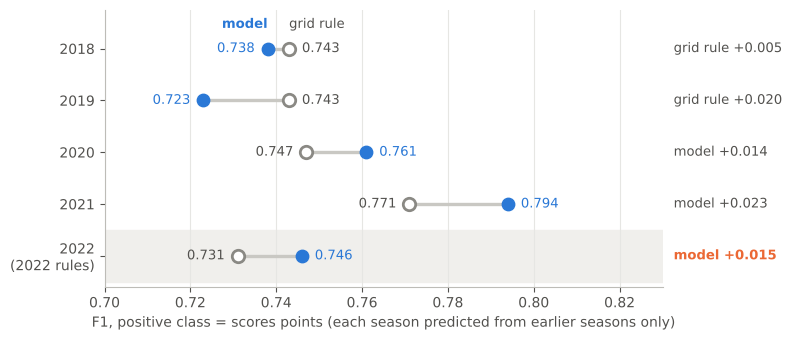

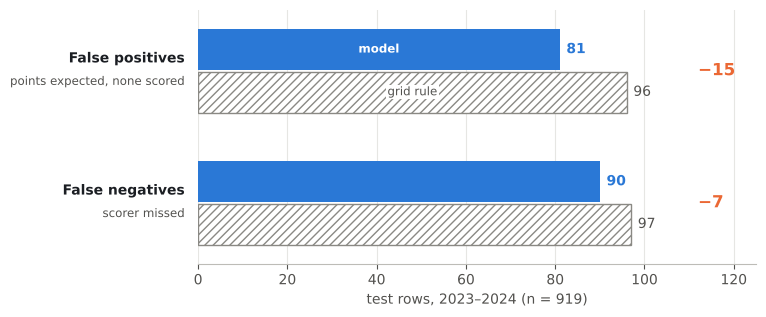

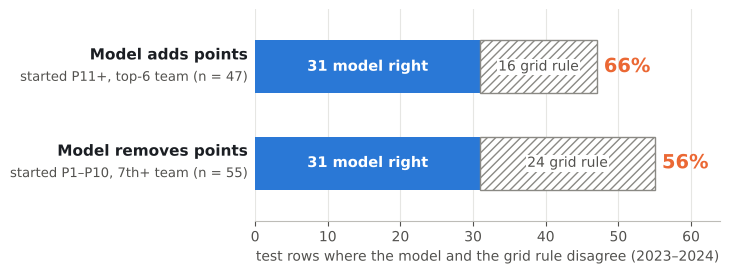

In [17]:
MODEL, REF, ACCENT, INK, INK2, GRID, BAND = "#2a78d6", "#8a8984", "#eb6834", "#1b1e23", "#52514e", "#e6e6e3", "#f0efec"
def style():
    plt.rcdefaults()
    plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "font.size": 10, "font.family": "DejaVu Sans",
                         "axes.edgecolor": "#bdbcb7", "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": GRID, "axes.axisbelow": True, "axes.labelcolor": INK2, "xtick.color": INK2,
                         "ytick.color": INK2, "legend.frameon": False})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight", facecolor="white"); plt.show()

# Figure A: validation F1 by season (dots on a common scale)
style()
v = by_season.iloc[::-1].reset_index(drop=True); v["m"], v["r"] = v["F1 model"].round(3), v["F1 reference"].round(3)
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.axhspan(-0.5, 0.5, color=BAND, zorder=0)
for i, r in v.iterrows():
    ax.plot([r.r, r.m], [i, i], color="#c9c8c3", lw=2.4, zorder=1)
    ax.scatter(r.r, i, s=80, facecolor="white", edgecolor=REF, lw=2, zorder=3)
    ax.scatter(r.m, i, s=80, color=MODEL, zorder=3)
    lo_ = min(r.m, r.r)
    for val_, col in ((r.m, MODEL), (r.r, INK2)):
        ax.text(val_ + (-0.003 if val_ == lo_ else 0.003), i, f"{val_:.3f}", va="center",
                ha="right" if val_ == lo_ else "left", fontsize=9.5, color=col)
    d = round(r.m - r.r, 3)
    ax.text(1.02, i, f"{'model' if d > 0 else 'grid rule'} +{abs(d):.3f}", transform=ax.get_yaxis_transform(), va="center",
            fontsize=9.5, color=ACCENT if r.season == 2022 else INK2, fontweight="bold" if r.season == 2022 else "normal")
top = len(v) - 1
ax.text(v.loc[top, "m"], top + 0.4, "model", color=MODEL, fontsize=9.5, ha="right", fontweight="bold")
ax.text(v.loc[top, "r"], top + 0.4, "grid rule", color=INK2, fontsize=9.5, ha="left")
ax.set_yticks(range(len(v)), [f"{s}\n(2022 rules)" if s >= 2022 else str(s) for s in v["season"]])
ax.set_xlim(0.70, 0.83); ax.set_ylim(-0.6, len(v) - 0.25); ax.grid(axis="y", visible=False)
ax.set_xlabel("F1, positive class = scores points (each season predicted from earlier seasons only)")
save(fig, "FINAL_A_validation_f1_by_season")

# Figure B: test errors (bars from zero, model solid, grid rule hatched)
style()
fig, ax = plt.subplots(figsize=(7.2, 3.3))
rows_ = [("FP", "False positives", "points expected, none scored"), ("FN", "False negatives", "scorer missed")]
for (k, lab, desc), yy in zip(rows_, [1.3, 0.0]):
    ax.barh(yy + 0.21, cm["model"][k], 0.4, color=MODEL)
    ax.barh(yy - 0.21, cm["reference"][k], 0.4, color="white", edgecolor=REF, hatch="////")
    ax.text(cm["model"][k] + 1.5, yy + 0.21, str(cm["model"][k]), va="center", color=MODEL, fontweight="bold")
    ax.text(cm["reference"][k] + 1.5, yy - 0.21, str(cm["reference"][k]), va="center", color=INK2)
    ax.text(-3, yy + 0.05, lab, ha="right", va="bottom", fontweight="bold", color=INK)
    ax.text(-3, yy - 0.05, desc, ha="right", va="top", fontsize=8.5, color=INK2)
    ax.text(112, yy, f"{cm['model'][k] - cm['reference'][k]:+d}".replace("-", "−"), va="center", color=ACCENT,
            fontweight="bold", fontsize=12)
ax.text(cm["model"]["FP"] / 2, 1.51, "model", ha="center", va="center", color="white", fontsize=8.5, fontweight="bold")
ax.text(cm["reference"]["FP"] / 2, 1.09, "grid rule", ha="center", va="center", color=INK2, fontsize=8.5,
        bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.set_yticks([]); ax.set_xlim(0, 125); ax.set_ylim(-0.6, 1.9); ax.spines["left"].set_visible(False); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"test rows, 2023–2024 (n = {len(test)})")
save(fig, "FINAL_B_test_errors")

# Figure C: disagreements with the grid rule
style()
fig, ax = plt.subplots(figsize=(6.0, 2.75))
for (title_, desc, right, wrong), yy in zip([("Model adds points", f"started P11+, top-6 team (n = {len(up)})",
                                               KEY["up_right"], len(up) - KEY["up_right"]),
                                              ("Model removes points", f"started P1–P10, 7th+ team (n = {len(down)})",
                                               KEY["down_right"], len(down) - KEY["down_right"])], [1.0, 0.0]):
    ax.barh(yy, right, 0.55, color=MODEL)
    ax.barh(yy, wrong, 0.55, left=right, color="white", edgecolor=REF, hatch="////")
    ax.text(right / 2, yy, f"{right} model right", ha="center", va="center", color="white", fontweight="bold", fontsize=10.5)
    ax.text(right + wrong / 2, yy, f"{wrong} grid rule", ha="center", va="center", color=INK2, fontsize=10,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.text(right + wrong + 1, yy, f"{right / (right + wrong):.0%}", va="center", color=ACCENT, fontweight="bold", fontsize=14)
    ax.text(-1, yy + 0.04, title_, ha="right", va="bottom", fontweight="bold", color=INK, fontsize=11)
    ax.text(-1, yy - 0.04, desc, ha="right", va="top", fontsize=9.5, color=INK2)
ax.set_yticks([]); ax.set_xlim(0, 64); ax.set_ylim(-0.6, 1.6); ax.spines["left"].set_visible(False); ax.grid(axis="y", visible=False)
ax.set_xlabel("test rows where the model and the grid rule disagree (2023–2024)", fontsize=10)
save(fig, "FINAL_C_disagreements")

In [18]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return o
(PROC / "final_key_numbers.json").write_text(json.dumps(clean(KEY), indent=1, ensure_ascii=False))
print(f"{len(KEY)} key numbers saved to data/processed/final_key_numbers.json")

70 key numbers saved to data/processed/final_key_numbers.json


## 8. Contributions and AI use
**Contributions.** Maximiliano Sandoval led this notebook (walk-forward evaluation, robustness and key numbers) and the
consistency review; Benjamín Toloza reviewed it and built the final views and the C3 repository record. Who did what in
every stage is listed in `docs/decision_record.md`, part 4.

**AI use.** Claude (Anthropic) was used to draft code and text for this notebook and the final presentation. The team
reran the notebook from top to bottom and checked that every number in the slides comes from its outputs
(`final_key_numbers.json`).